In [8]:
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from IPython.display import clear_output
from matplotlib.patches import Patch
from networkx import (
    barabasi_albert_graph,
    erdos_renyi_graph,
    watts_strogatz_graph,
)

n_normal_agents = 100
n_stubborn_agents = int(n_normal_agents * 0)
n_malicious_agents = 10  #  int(n_normal_agents * 0.1)
epsilon = 0.1
initial_opinion_min = -0.6
initial_opinion_max = 0.6
malicious_opinion = -0.6
malicious_target = 1
steps = 100
delay = 0
seed = 1
malicious_speed = (malicious_target - malicious_opinion) / steps


def init_grid_erdos(n_agents, p_edge=1):
    grid = nx.to_numpy_array(erdos_renyi_graph(n_agents, p_edge, seed=seed))
    np.fill_diagonal(grid, 1)
    return grid


def init_grid_barbasi(n_agents, edges=6):
    grid = nx.to_numpy_array(barabasi_albert_graph(n_agents, edges, seed=seed))
    np.fill_diagonal(grid, 1)
    return grid


def init_grid_watts(n_agents, k_neighbors=5, p_rewire=0.2):
    grid = nx.to_numpy_array(
        watts_strogatz_graph(n_agents, k_neighbors, p_rewire, seed=seed)
    )
    np.fill_diagonal(grid, 1)
    return grid


def transform(x):
    return np.minimum(x + malicious_speed, malicious_target)


np.random.seed(seed)

init_grid = lambda x: init_grid_erdos(x)


In [9]:
n_agents = n_normal_agents + n_stubborn_agents + n_malicious_agents
state = np.concatenate(
    [
        np.linspace(initial_opinion_min, initial_opinion_max, n_normal_agents),
        np.random.uniform(initial_opinion_min, initial_opinion_max, n_stubborn_agents),
        np.full(n_malicious_agents, malicious_opinion),
    ]
)

normal = np.zeros(n_agents, dtype=bool)
stubborn = np.zeros(n_agents, dtype=bool)
malicious = np.zeros(n_agents, dtype=bool)
normal[:n_normal_agents] = True
stubborn[n_normal_agents : n_normal_agents + n_stubborn_agents] = True
malicious[n_normal_agents + n_stubborn_agents :] = True
history = [state.copy()]


In [10]:
grid = init_grid(n_agents)
network = nx.from_numpy_array(grid)
network.remove_edges_from(nx.selfloop_edges(network))


In [11]:
colors = {"normal": "tab:blue", "stubborn": "tab:orange", "malicious": "tab:red"}
agent_types = np.where(stubborn, "stubborn", np.where(malicious, "malicious", "normal"))


def layout(graph):
    if graph.number_of_edges() == 0:
        communities = [{node} for node in graph.nodes]
    else:
        communities = list(nx.community.greedy_modularity_communities(graph))

    centers = nx.circular_layout(nx.complete_graph(len(communities)), scale=3)
    positions = {}

    for i, nodes in enumerate(communities):
        local_positions = nx.spring_layout(graph.subgraph(nodes), seed=seed, scale=0.8)
        positions.update(
            {node: point + centers[i] for node, point in local_positions.items()}
        )

    return positions


def draw(state, history, active_grid, step):
    figure, (opinion_axes, network_axes) = plt.subplots(1, 2, figsize=(16, 6))
    values = np.asarray(history)

    for index in range(n_agents):
        kind = agent_types[index]
        opinion_axes.plot(
            values[:, index],
            color=colors[kind],
            zorder=1 if kind == "normal" else 2,
        )

    change_from_initial = values - values[0]
    mean_change = np.mean(change_from_initial, axis=1)
    variance_change = np.var(change_from_initial, axis=1)
    (mean_line,) = opinion_axes.plot(
        mean_change,
        color="black",
        linewidth=2.5,
        linestyle="--",
        label="mean(current - initial)",
        zorder=4,
    )
    (variance_line,) = opinion_axes.plot(
        variance_change,
        color="tab:purple",
        linewidth=2.5,
        linestyle=":",
        label="variance(current - initial)",
        zorder=4,
    )

    opinion_axes.set(
        title=f"opinion at step {step}",
        xlabel="step",
        ylabel="opinion",
    )
    opinion_axes.legend(
        handles=[
            *[Patch(color=color, label=name) for name, color in colors.items()],
            mean_line,
            variance_line,
        ]
    )

    active_network = nx.from_numpy_array(active_grid)
    active_network.remove_edges_from(nx.selfloop_edges(active_network))
    inactive_network = network.copy()
    inactive_network.remove_edges_from(active_network.edges)
    positions = layout(active_network)
    nx.draw_networkx_edges(
        inactive_network,
        positions,
        ax=network_axes,
        edge_color="gray",
        style="dashed",
        alpha=0.1,
    )
    nx.draw_networkx_edges(
        active_network,
        positions,
        ax=network_axes,
        edge_color="black",
        alpha=0.45,
    )
    nx.draw_networkx_nodes(
        active_network,
        positions,
        ax=network_axes,
        node_color=[colors[kind] for kind in agent_types],
        node_size=300,
    )
    nx.draw_networkx_labels(
        active_network,
        positions,
        ax=network_axes,
        labels={i: f"{round(state[i], 2)}" for i in range(n_agents)},
        font_color="white",
        font_size=6,
    )
    network_axes.set_title("network")
    network_axes.axis("off")
    figure.tight_layout()
    plt.show()


In [14]:
def run_one(state):
    history = [state.copy()]
    init_state = state.copy()

    for step in range(steps + 1):
        grid_copy = grid.copy()
        differences = np.abs(state[:, None] - state[None, :])
        grid_copy[differences > epsilon] = 0

        # clear_output(wait=True)
        # draw(state, history, grid_copy, step)

        next_state = (grid_copy @ state) / grid_copy.sum(axis=1)
        next_state[malicious] = transform(state[malicious])
        next_state[stubborn] = state[stubborn]
        state = next_state
        history.append(state.copy())
        time.sleep(delay)

    draw(state, history, grid_copy, step)
    print(np.mean(state - init_state), np.var(state - init_state))


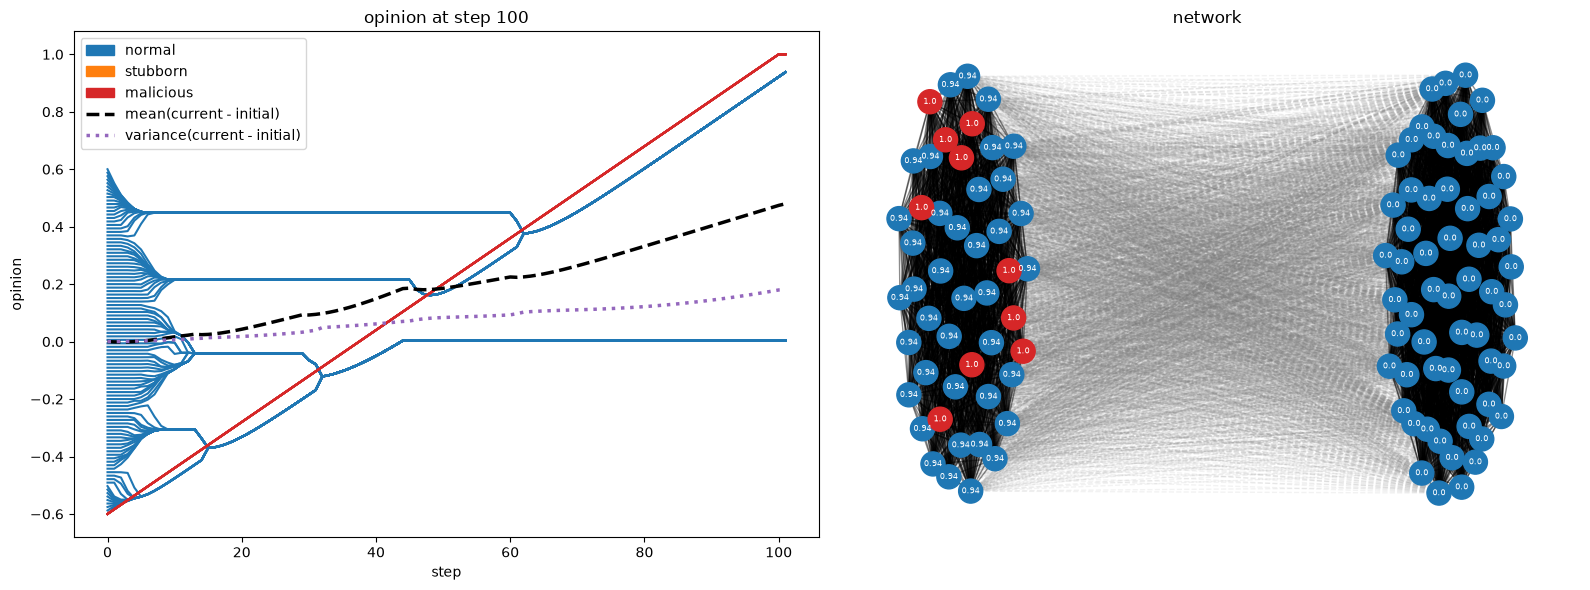

0.47973333443580396 0.180652008957131


In [15]:
run_one(state)
